In [1]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# 2. LOAD DATA
df = pd.read_csv("thane_weather_2022_2026.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")

In [3]:
# 3. CONVERT DAILY DATA TO MONTHLY AVERAGES
monthly = df.resample("MS").mean(numeric_only=True)

# Use the longest continuous period found earlier
monthly = monthly.loc["2023-03":"2026-09"]

print(monthly.head())
print("Missing values:\n", monthly.isnull().sum())

              year  month   day     temp_c     temp_f  forecast_high_c  \
date                                                                     
2023-03-01  2023.0    3.0  26.5  24.600000  76.300000        33.300000   
2023-04-01  2023.0    4.0  15.5  27.833333  82.000000        37.033333   
2023-05-01  2023.0    5.0  16.0  28.774194  84.225806        35.677419   
2023-06-01  2023.0    6.0  15.5  28.900000  84.133333        33.166667   
2023-07-01  2023.0    7.0  16.0  26.870968  80.225806        28.580645   

            forecast_high_f  forecast_low_c  forecast_low_f  humidity_pct  \
date                                                                        
2023-03-01        92.100000       23.000000       73.500000     73.400000   
2023-04-01        98.733333       25.966667       78.733333     70.400000   
2023-05-01        96.225806       27.548387       81.806452     80.258065   
2023-06-01        91.600000       27.700000       82.133333     82.900000   
2023-07-01        8

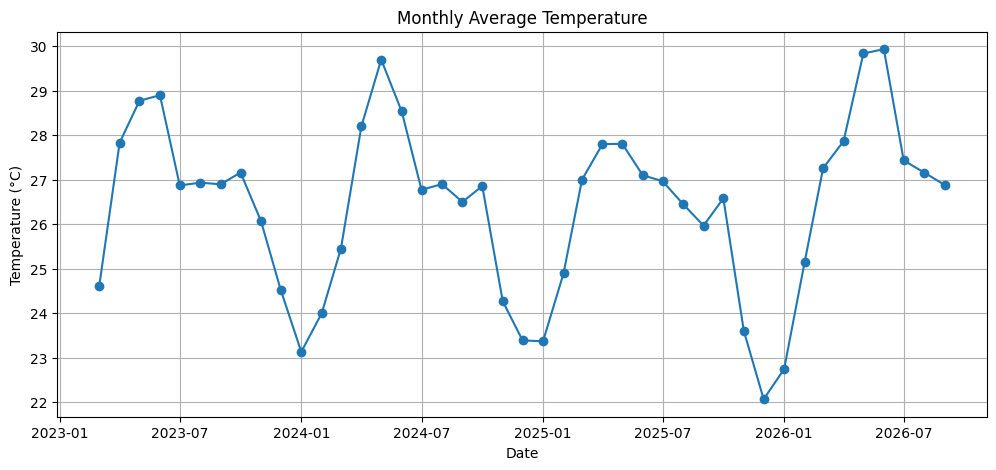

In [4]:
# 4. VISUALIZE TEMPERATURE
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly["temp_c"], marker="o")
plt.title("Monthly Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

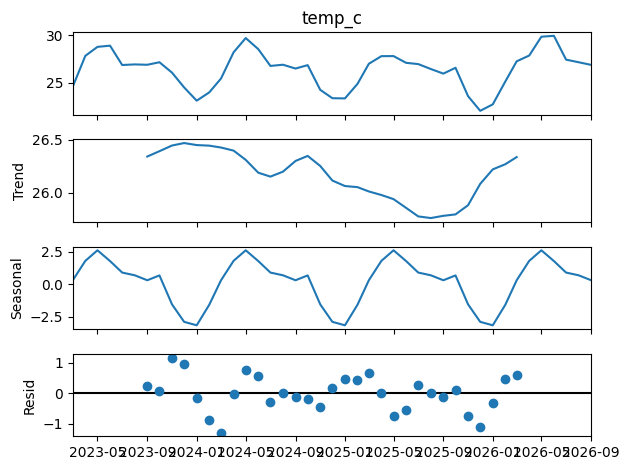

In [5]:
# 5. CHECK SEASONALITY
decomposition = seasonal_decompose(
    monthly["temp_c"],
    model="additive",
    period=12
)

decomposition.plot()
plt.show()

In [6]:
# 6. DEFINE TARGET AND EXOGENOUS VARIABLES
target = monthly["temp_c"]

exog = monthly[["humidity_pct", "wind_speed_kmh"]]

# Keep only rows where all selected variables are available
data = pd.concat([target, exog], axis=1).dropna()

target = data["temp_c"]
exog = data[["humidity_pct", "wind_speed_kmh"]]

In [7]:
# 7. TRAIN-TEST SPLIT
train_target = target.iloc[:-12]
test_target = target.iloc[-12:]

train_exog = exog.iloc[:-12]
test_exog = exog.iloc[-12:]

In [9]:
# 8. FIT THE SEASONAL SARIMAX MODEL

model = SARIMAX(
    train_target,
    exog=train_exog,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

result = model.fit()

print(result.summary())

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


                                     SARIMAX Results                                      
Dep. Variable:                             temp_c   No. Observations:                   31
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -23.674
Date:                            Fri, 16 Oct 2026   AIC                             61.348
Time:                                    10:58:20   BIC                             67.581
Sample:                                03-01-2023   HQIC                            62.207
                                     - 09-01-2025                                         
Covariance Type:                              opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
humidity_pct      -0.0363      0.042     -0.857      0.392      -0.119       0.047
wind_speed_kmh     0.10

In [10]:
# 9. FORECAST
forecast = result.forecast(
    steps=len(test_target),
    exog=test_exog
)

forecast.index = test_target.index

In [11]:
# 10. EVALUATION
mae = mean_absolute_error(test_target, forecast)
rmse = np.sqrt(mean_squared_error(test_target, forecast))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 1.14
RMSE: 1.27


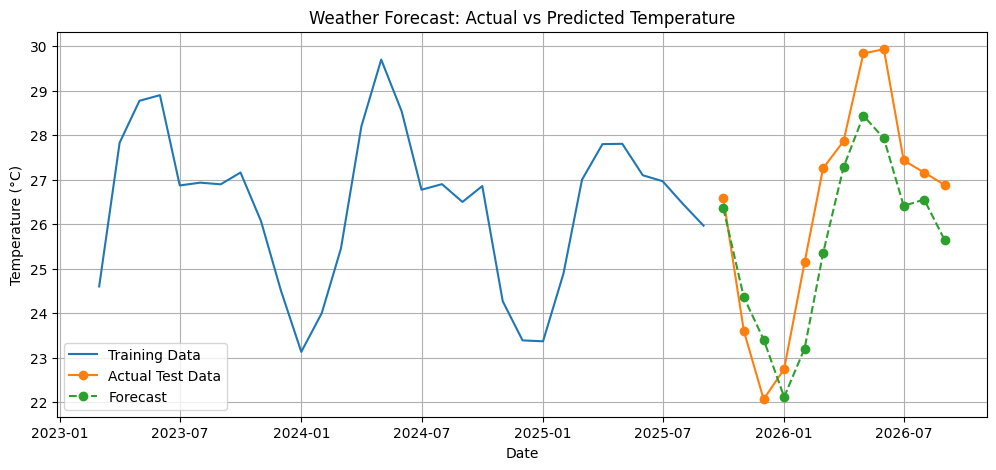

In [12]:
# 11. PLOT ACTUAL VS FORECAST
plt.figure(figsize=(12, 5))

plt.plot(train_target.index, train_target, label="Training Data")
plt.plot(test_target.index, test_target, marker="o", label="Actual Test Data")
plt.plot(forecast.index, forecast, marker="o", linestyle="--",
         label="Forecast")

plt.title("Weather Forecast: Actual vs Predicted Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()